# 01: Customer Intelligence & Lifetime Value Modeling

**RetentionIQ Portfolio Showcase** | Dataset: *Online Retail II*

> **Synthetic data.** This notebook runs on `data/sample/`, generated with a seeded random generator by `scripts/make_sample.py` to mimic the real schema. It is **not** a sample of the real dataset: outputs demonstrate the method, not real findings. Real results: `docs/RESULTS.md`.

This notebook demonstrates behavioral customer intelligence on non-contractual e-commerce transactions:
1. **Exploratory Data Analysis & Value Concentration**: Measuring revenue skew and calculating the Gini coefficient.
2. **RFM Behavioral Segmentation**: Rule-based quintile scoring and customer lifecycle categorizations.
3. **Unsupervised Clustering (K-Means)**: Validating behavioral clusters against heuristic RFM.
4. **Probabilistic Customer Lifetime Value (BG/NBD + Gamma-Gamma)**: Predicting future transaction frequency and monetary value over a held-out 90-day window.
5. **Cohort Retention Matrix**: Visualizing month-over-month cohort decay.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import calibration_and_holdout_data
from retentioniq.analytics.customers import rfm_scores

# Configure colorblind-safe styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
cb_blue, cb_orange, cb_green = '#1f77b4', '#ff7f0e', '#2ca02c'

# Load sample dataset
sample_path = Path('data/sample/online_retail_sample.parquet')
if not sample_path.exists():
    sample_path = Path('../data/sample/online_retail_sample.parquet')
orders = pd.read_parquet(sample_path)
print(f'Loaded {len(orders):,} transactions for {orders["customer_id"].nunique():,} unique customers.')
orders.head(3)

Loaded 13,581 transactions for 2,500 unique customers.


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,order_value
0,INV-12078-01,SKU-908,HEART OF WICKER SMALL,2,2010-12-01 09:00:00,1.45,12078,United Kingdom,2.90
1,INV-11730-01,SKU-621,REGENCY CAKESTAND 3 TIER,1,2010-12-01 10:00:00,12.75,11730,United Kingdom,12.75
2,INV-11730-01,SKU-780,WHITE HANGING HEART T-LIGHT HOLDER,2,2010-12-01 10:00:00,2.55,11730,United Kingdom,5.10


## 1. Value Concentration & The Pareto Principle

In non-contractual commerce, revenue is typically hyper-concentrated in a small tier of high-value customers. Below we compute customer lifetime spend, calculate the Gini coefficient, and plot the cumulative Lorenz curve.

Top 10% Revenue Share: 34.4%
Top 1% Revenue Share:  5.7%
Gini Coefficient:      0.501


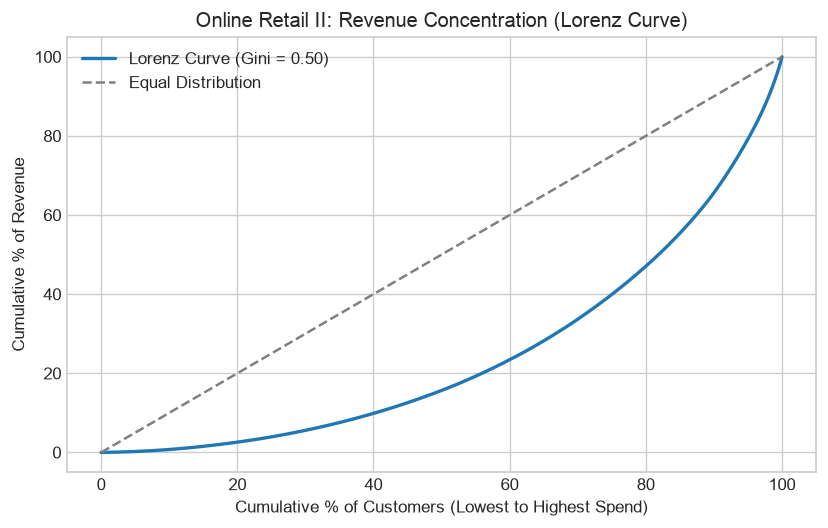

In [2]:
cust_ltv = orders.groupby('customer_id')['order_value'].sum().sort_values(ascending=False)
total_rev = cust_ltv.sum()
n_cust = len(cust_ltv)

top_10_pct_rev = cust_ltv.iloc[:int(n_cust * 0.10)].sum() / total_rev
top_1_pct_rev = cust_ltv.iloc[:int(n_cust * 0.01)].sum() / total_rev

# Gini coefficient calculation
sorted_ltv = np.sort(cust_ltv.values)
index = np.arange(1, n_cust + 1)
gini = (np.sum((2 * index - n_cust - 1) * sorted_ltv)) / (n_cust * np.sum(sorted_ltv))

print(f'Top 10% Revenue Share: {top_10_pct_rev:.1%}')
print(f'Top 1% Revenue Share:  {top_1_pct_rev:.1%}')
print(f'Gini Coefficient:      {gini:.3f}')

# Lorenz Curve
cum_customers = np.linspace(0, 100, n_cust)
cum_revenue = np.cumsum(np.sort(cust_ltv.values)) / total_rev * 100

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
ax.plot(cum_customers, cum_revenue, color=cb_blue, linewidth=2, label=f'Lorenz Curve (Gini = {gini:.2f})')
ax.plot([0, 100], [0, 100], '--', color='gray', label='Equal Distribution')
ax.set_xlabel('Cumulative % of Customers (Lowest to Highest Spend)')
ax.set_ylabel('Cumulative % of Revenue')
ax.set_title('Online Retail II: Revenue Concentration (Lorenz Curve)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 2. RFM Behavioral Segmentation

We construct Recency (days since last order), Frequency (distinct purchase invoices), and Monetary Value (total spend) per customer. Customers are assigned to quintiles (1-5) and mapped to canonical lifecycle segments: Champions, Loyal, Potential Loyalists, At Risk, Hibernating, and Lost.

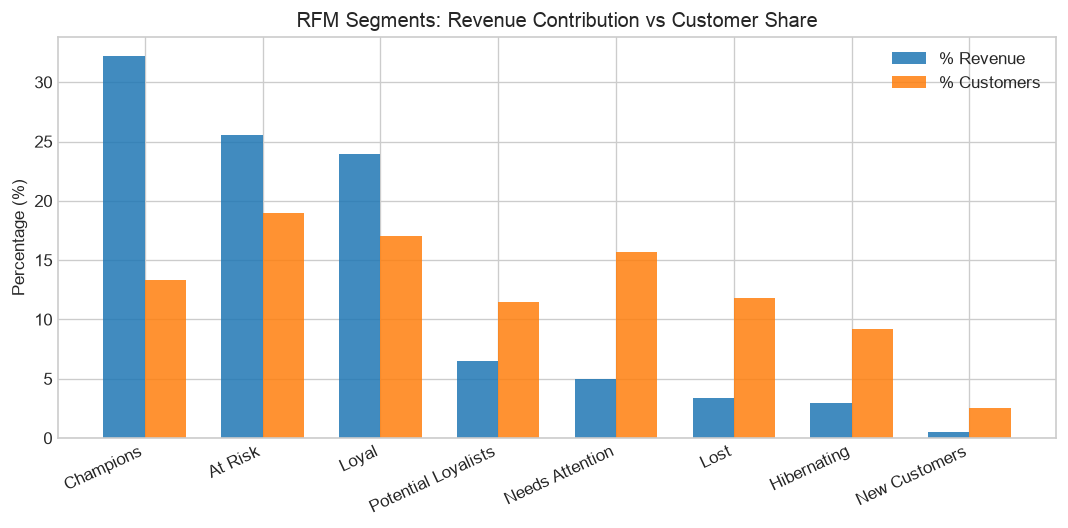

In [3]:
snapshot = orders['invoice_date'].max() + pd.Timedelta(days=1)
rfm_df = rfm_scores(orders.rename(columns={'invoice_date': 'order_date'}), snapshot)

# Summary by segment
rfm_summary = rfm_df.groupby('rfm_segment').agg(
    customers=('customer_id', 'count'),
    total_revenue=('monetary', 'sum'),
    avg_monetary=('monetary', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_recency=('recency_days', 'mean')
).reset_index()
rfm_summary['revenue_share'] = rfm_summary['total_revenue'] / rfm_summary['total_revenue'].sum()
rfm_summary = rfm_summary.sort_values('total_revenue', ascending=False)

# Plot Segment Revenue Share vs Customer Share
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)
x = np.arange(len(rfm_summary))
width = 0.35
ax.bar(x - width/2, rfm_summary['revenue_share'] * 100, width, label='% Revenue', color=cb_blue, alpha=0.85)
ax.bar(x + width/2, (rfm_summary['customers'] / n_cust) * 100, width, label='% Customers', color=cb_orange, alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(rfm_summary['rfm_segment'], rotation=25, ha='right')
ax.set_ylabel('Percentage (%)')
ax.set_title('RFM Segments: Revenue Contribution vs Customer Share')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Probabilistic Customer Lifetime Value (BG/NBD + Gamma-Gamma)

Heuristic RFM describes past behavior but cannot forecast future spend. We hold out the last 90 days of transaction history and fit:
1. **Beta-Geometric/Negative Binomial (BG/NBD)** to model repeat transaction timing and dropout rates.
2. **Gamma-Gamma submodel** to estimate monetary spend per transaction.

Combined, these predict expected 90-day forward customer value, evaluated against actual holdout purchases.

BG/NBD 90-day Purchase Frequency MAE: 0.4080
CLV vs Actual Holdout Spend Spearman Rank Correlation: 0.0609


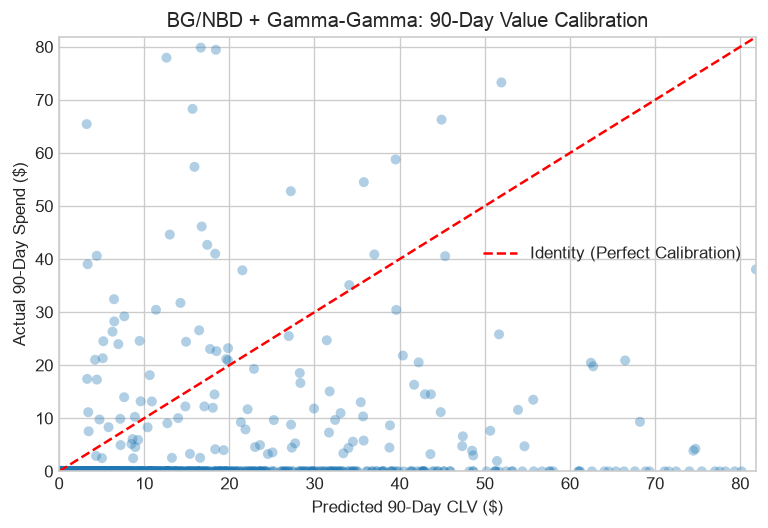

In [4]:
t_max = orders['invoice_date'].max()
cal_end = t_max - pd.Timedelta(days=90)

clv_data = calibration_and_holdout_data(
    orders,
    customer_id_col='customer_id',
    datetime_col='invoice_date',
    calibration_period_end=cal_end,
    observation_period_end=t_max,
    monetary_value_col='order_value'
)

# 1. Fit BG/NBD
bgf = BetaGeoFitter(penalizer_coef=0.01)
bgf.fit(clv_data['frequency_cal'], clv_data['recency_cal'], clv_data['T_cal'])
pred_purchases = bgf.conditional_expected_number_of_purchases_up_to_time(
    90, clv_data['frequency_cal'], clv_data['recency_cal'], clv_data['T_cal']
)
clv_data['pred_purchases_90d'] = pred_purchases

# 2. Fit Gamma-Gamma on repeat purchasers
rep = clv_data[(clv_data['frequency_cal'] > 0) & (clv_data['monetary_value_cal'] > 0)]
ggf = GammaGammaFitter(penalizer_coef=0.01)
ggf.fit(rep['frequency_cal'], rep['monetary_value_cal'])
pred_monetary = ggf.conditional_expected_average_profit(
    clv_data['frequency_cal'], clv_data['monetary_value_cal']
).fillna(rep['monetary_value_cal'].mean())
clv_data['pred_clv_90d'] = clv_data['pred_purchases_90d'] * pred_monetary
clv_data['actual_spend_90d'] = clv_data['frequency_holdout'] * clv_data['monetary_value_holdout']

# Evaluation
mae_bgnbd = float(np.mean(np.abs(clv_data['pred_purchases_90d'] - clv_data['frequency_holdout'])))
spearman_corr = float(spearmanr(clv_data['pred_clv_90d'], clv_data['actual_spend_90d']).statistic)
print(f'BG/NBD 90-day Purchase Frequency MAE: {mae_bgnbd:.4f}')
print(f'CLV vs Actual Holdout Spend Spearman Rank Correlation: {spearman_corr:.4f}')

# Scatter of Predicted vs Actual 90d Spend
fig, ax = plt.subplots(figsize=(6.5, 4.5), dpi=120)
ax.scatter(clv_data['pred_clv_90d'], clv_data['actual_spend_90d'], alpha=0.35, color=cb_blue, edgecolors='none')
max_val = max(clv_data['pred_clv_90d'].quantile(0.99), clv_data['actual_spend_90d'].quantile(0.99))
ax.plot([0, max_val], [0, max_val], 'r--', label='Identity (Perfect Calibration)')
ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
ax.set_xlabel('Predicted 90-Day CLV ($)')
ax.set_ylabel('Actual 90-Day Spend ($)')
ax.set_title('BG/NBD + Gamma-Gamma: 90-Day Value Calibration')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Cohort Retention Heatmap

We group customers by their initial acquisition month and trace retention rates across their first 6 calendar months.

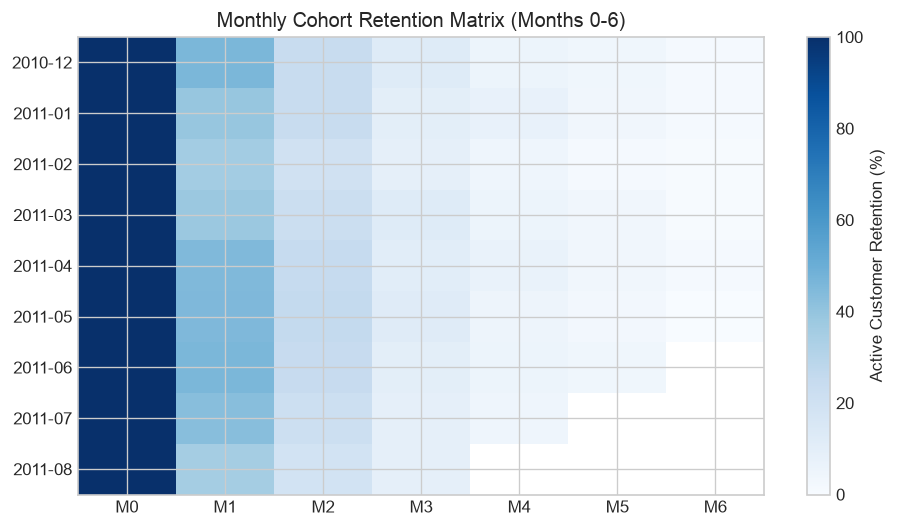

In [5]:
orders_clean = orders.rename(columns={'invoice_date': 'order_date'}).copy()
first_dates = orders_clean.groupby('customer_id')['order_date'].min().dt.to_period('M')
orders_clean['cohort_month'] = orders_clean['customer_id'].map(first_dates)
orders_clean['order_month'] = orders_clean['order_date'].dt.to_period('M')

orders_clean['month_offset'] = (
    (orders_clean['order_month'].dt.year - orders_clean['cohort_month'].dt.year) * 12
    + (orders_clean['order_month'].dt.month - orders_clean['cohort_month'].dt.month)
)

cohort_sizes = orders_clean.groupby('cohort_month')['customer_id'].nunique()
retention = orders_clean[orders_clean['month_offset'] <= 6].groupby(
    ['cohort_month', 'month_offset']
)['customer_id'].nunique().unstack()
retention_pct = retention.divide(cohort_sizes, axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
im = ax.imshow(retention_pct.values, cmap='Blues', aspect='auto', vmin=0, vmax=100)
ax.set_xticks(np.arange(len(retention_pct.columns)))
ax.set_xticklabels([f'M{c}' for c in retention_pct.columns])
ax.set_yticks(np.arange(len(retention_pct.index)))
ax.set_yticklabels([str(p) for p in retention_pct.index])
plt.colorbar(im, ax=ax, label='Active Customer Retention (%)')
ax.set_title('Monthly Cohort Retention Matrix (Months 0-6)')
plt.tight_layout()
plt.show()